In [1]:

import numpy as np 
import pandas as pd 
import seaborn as sns 
import scipy.stats as st 
import matplotlib.pyplot as plt 
import plotly.graph_objects as go 

arr1 = np.array([10,20,30,40,50,60])
arr2 = np.array([1,19,19,19,1,3,4])
arr1

array([10, 20, 30, 40, 50, 60])

In [15]:

print("Mean: ",arr1.mean())
print("Median: ",np.median(arr1))
print("Mode: ",st.mode(arr2))


Mean:  35.0
Median:  35.0
Mode:  ModeResult(mode=np.int64(19), count=np.int64(3))


In [20]:

# ================== problem with mean median ==============
arr1 = np.array([-10,-5,5,10])
arr2 = np.array([-20,-10,-5,5,10,20])


print("="*50)
print("Mean: ",arr1.mean())
print("Median: ",np.median(arr1))


print("="*50)
print("Mean: ",arr2.mean())
print("Median: ",np.median(arr2))



Mean:  0.0
Median:  0.0
Mean:  0.0
Median:  0.0


In [30]:

# ================== Soln of  the above problem ==================
""" 
Measure of dispersion, variation or variability
"""
print("variance arr1: ",arr1.var())
print("variance arr2: ",arr2.var())

print("std arr1",arr1.std())
print("std arr2",arr2.std())

n = len(arr1)
dif_sum = 0 
for i in arr1:
    dif_sum += (arr1.mean()-i)**2
print("\nvariance manual calculation: ",(dif_sum)/n)
print()
np.sqrt((dif_sum/n))

variance arr1:  62.5
variance arr2:  175.0
std arr1 7.905694150420948
std arr2 13.228756555322953

variance manual calculation:  62.5



np.float64(7.905694150420948)

In [32]:

# probability distribution table:
# probability distribution fn (PDF,PMF,CDF)
# example: 4.5:
df = pd.DataFrame({
    "Demand": [1,2,3,4],
    "Prob_Demand": [1/6,1/3,1/3,1/6]
})
df 


,Demand,Prob_Demand
0,1,0.166667
1,2,0.333333
2,3,0.333333
3,4,0.166667


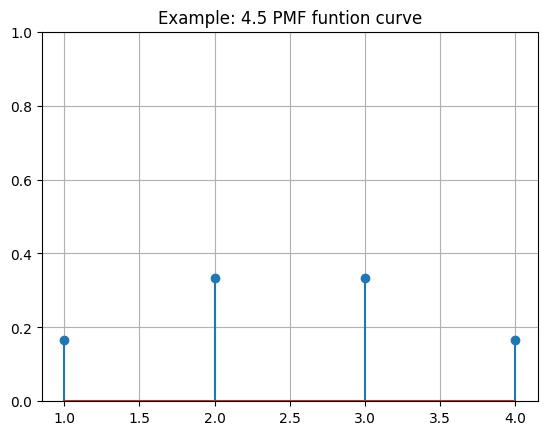

In [50]:

plt.title("Example: 4.5 PMF funtion curve")
plt.stem(df["Demand"],df["Prob_Demand"])
plt.grid()
plt.ylim(0,1)
plt.show()


In [51]:

# cdf of (PMF)
df["CDF"] = df["Prob_Demand"].cumsum()
df

,Demand,Prob_Demand,CDF
0,1,0.166667,0.166667
1,2,0.333333,0.500000
2,3,0.333333,0.833333
3,4,0.166667,1.000000


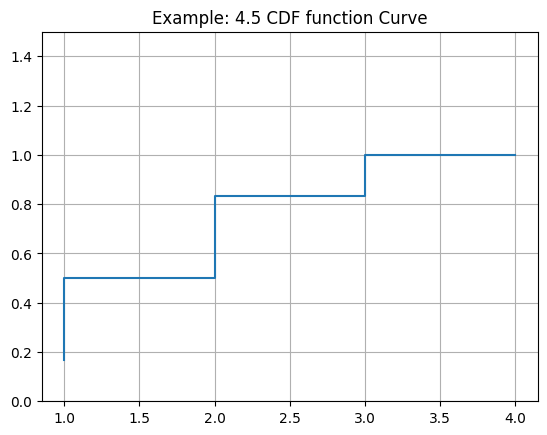

In [ ]:

plt.step(x=df["Demand"],y=df["CDF"],)
plt.title("Example: 4.5 CDF function Curve")
plt.ylim(0,1.5)
plt.grid(True)
plt.show()


# Join and Marginal Probability:

In [2]:
titanic = sns.load_dataset('titanic')
titanic.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [73]:
total_passerger = len(titanic["survived"])
total_passerger

891

In [69]:
pd.crosstab(titanic["survived"],titanic["pclass"])

pclass,1,2,3
survived,,,
0,80,97,372
1,136,87,119


In [ ]:
# join probability:
print("join_probability_of(pclass=1,survived=0): ", 80/total_passerger)
print("join_probability_of(pclass=1,survived=1): ", 136/total_passerger)
pd.crosstab(titanic["survived"],titanic['pclass'],normalize='all')

join_probability_of(pclass=1,survived=0):  0.08978675645342311
join_probability_of(pclass=1,survived=1):  0.1526374859708193


pclass,1,2,3
survived,,,
0,0.089787,0.108866,0.417508
1,0.152637,0.097643,0.133558


In [84]:

print('class-1 e koto jon passerger ase : ',(80+136)/total_passerger)
print('mara gese e koto jon passerger : ',(80+97+372)/total_passerger)

# marginal probability:
pd.crosstab(titanic["survived"],titanic['pclass'],margins=True,normalize='all')


class-1 e koto jon passerger ase :  0.24242424242424243
mara gese e koto jon passerger :  0.6161616161616161


pclass,1,2,3,All
survived,,,,
0,0.089787,0.108866,0.417508,0.616162
1,0.152637,0.097643,0.133558,0.383838
All,0.242424,0.206510,0.551066,1.000000



# 4.11:


In [ ]:

# x>=0 
x = np.linspace(0,1,100)
# y>=0
y = np.linspace(0,1,100)
data = []
for i in x:
    for j in y:
        z = 24 * i * j 
        if (i+j)>1:
            z = 0 
        data.append({"X":i,"Y":j,"Z":z})
df = pd.DataFrame(data)
df.head(5)


,X,Y,Z
0,0.0,0.000000,0.0
1,0.0,0.010101,0.0
2,0.0,0.020202,0.0
3,0.0,0.030303,0.0
4,0.0,0.040404,0.0


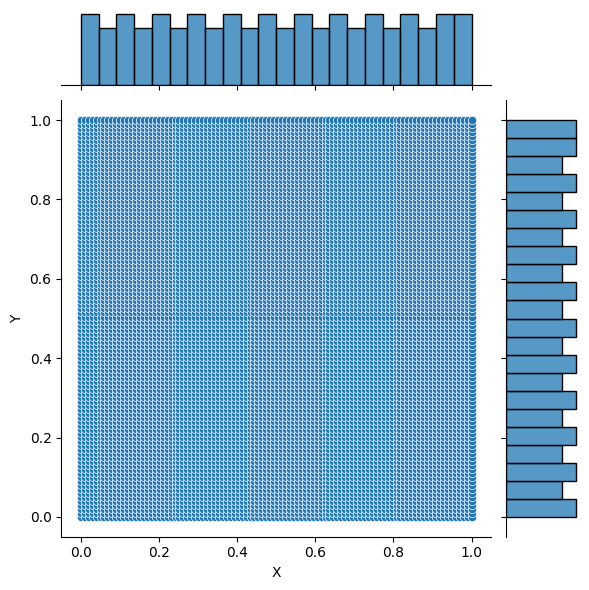

In [96]:

sns.jointplot(x=df["X"],y=df['Y'],kind="scatter")
plt.show()

[[0.         0.        ]
 [0.01010101 0.01010101]]


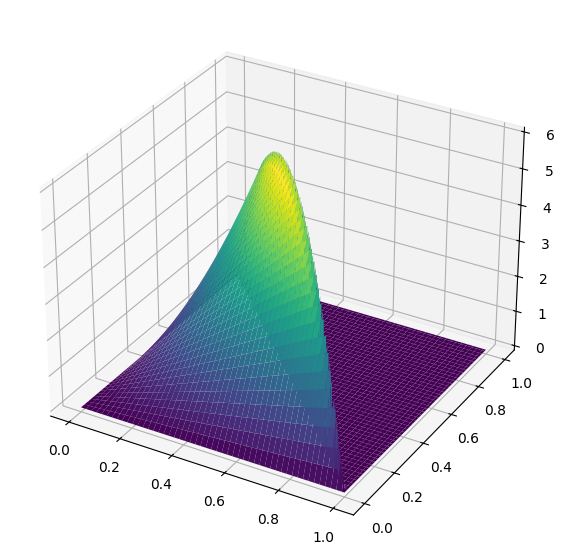

In [ ]:
# plot surface want 2D value
X = df["X"].values.reshape(100,100)
Y = df["Y"].values.reshape(100,100)
Z = df["Z"].values.reshape(100,100)
print(X[:2,:2])
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111,projection="3d")
ax.plot_surface(X,Y,Z,cmap="viridis")
plt.show()

In [ ]:

trace1 = go.Surface(x=X,y=Y,z=Z)
data = [trace1]
layout = go.Layout(
    title="3d join plot",
    scene=dict(
        xaxis_title="X-Axis",
        yaxis_title="y_Axis",
        zaxis_title="Density"
    ),
    template='plotly_dark',
    margin=dict(l=5,r=5,t=40)
    
)
fig = go.Figure(data=data,layout=layout)
fig.show()


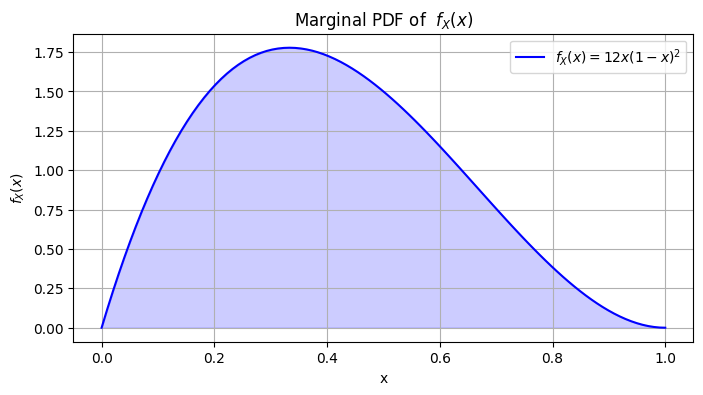

In [21]:

x_range = np.linspace(0, 1, 100)
fx = 12 * x_range * (1 - x_range)**2

plt.figure(figsize=(8, 4))
plt.plot(x_range, fx, color='blue', label='$f_X(x) = 12x(1-x)^2$')
plt.fill_between(x_range, fx, color='blue', alpha=0.2)
plt.title("Marginal PDF of  $f_X(x)$")
plt.xlabel("x")
plt.ylabel("$f_X(x)$")
plt.legend()
plt.grid(True)
plt.show()

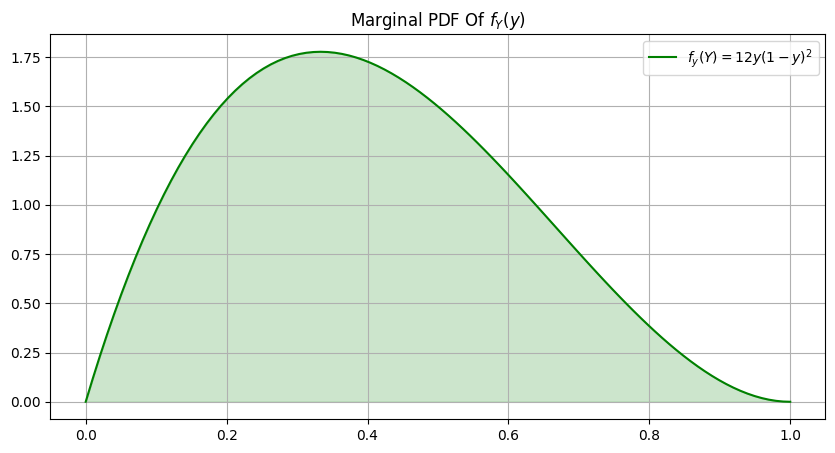

In [22]:

y_range = np.linspace(0,1,100)
fy = 12*y_range*(1-y_range)**2 

plt.figure(figsize=(10,5))
plt.plot(y_range,fy,color="green",label="$f_y(Y) = 12y(1-y)^2$")
plt.fill_between(y_range,fy,color='green',alpha=0.2)
plt.title("Marginal PDF Of $f_Y(y)$")
plt.legend()
plt.grid()
plt.show()


# 4.4: Estimator of means, variance and correlation: 


In [3]:

# auto corelation utility:
def autocorelation(data:np.array)->np.array:
    from scipy import signal
    # mean centering:
    data_centred = data - data.mean()
    #find the co-relation:
    corr = signal.correlate(data_centred,data_centred,mode='full')
    
    # do normalizing:
    autocorr = corr/np.max(corr)
    
    # see from middle:
    n = len(autocorr)//2 
    return autocorr[n:]

In [11]:


# Data is IID:
true_mean = 50
true_std = 100
no_of_sample = 1000

data = np.random.normal(loc=true_mean,scale=true_std,size=no_of_sample)

# check that auto co-relation:
""" 
lag0 = 1 then other's almost zero then there is no auto co-relation.
if decrease like: 0.9,0.8,0.7 then have auto co-reation
"""
print("="*50)
autocor = autocorelation(data)
print(f"Lag 0 autocorelation: {autocor[0]:.2f}")
print(f"Lag 1 autocorelation: {autocor[1]:.2f}")
print(f"Lag 2 autocorelation: {autocor[2]:.2f}")
print(f"Lag 3 autocorelation: {autocor[3]:.2f}")
print("="*50)

print(f"True Mean: {true_mean}, True_standard_deviation: {true_std}")
print(f"Estimated Mean: {data.mean():.2f}, Estimated_standard_deviation: {data.std():2f}")


Lag 0 autocorelation: 1.00
Lag 1 autocorelation: -0.00
Lag 2 autocorelation: -0.07
Lag 3 autocorelation: 0.03
True Mean: 50, True_standard_deviation: 100
Estimated Mean: 48.99, Estimated_standard_deviation: 105.186793


<br>

### How to generate auto Covariance-Stationary data?

formula: 

$X_t = \phi \times X_{t-1} + \eta_t$

- Xt​: current value
- ϕ (Phi): We will control Autocorrelation with this parameter. If phi=0 IID data, if phi>0 positive coreation else if phi<0 then negative auto co relation.
- ϵt​ (Error): Basincally a IID noise (generally take from  np.random.normal).

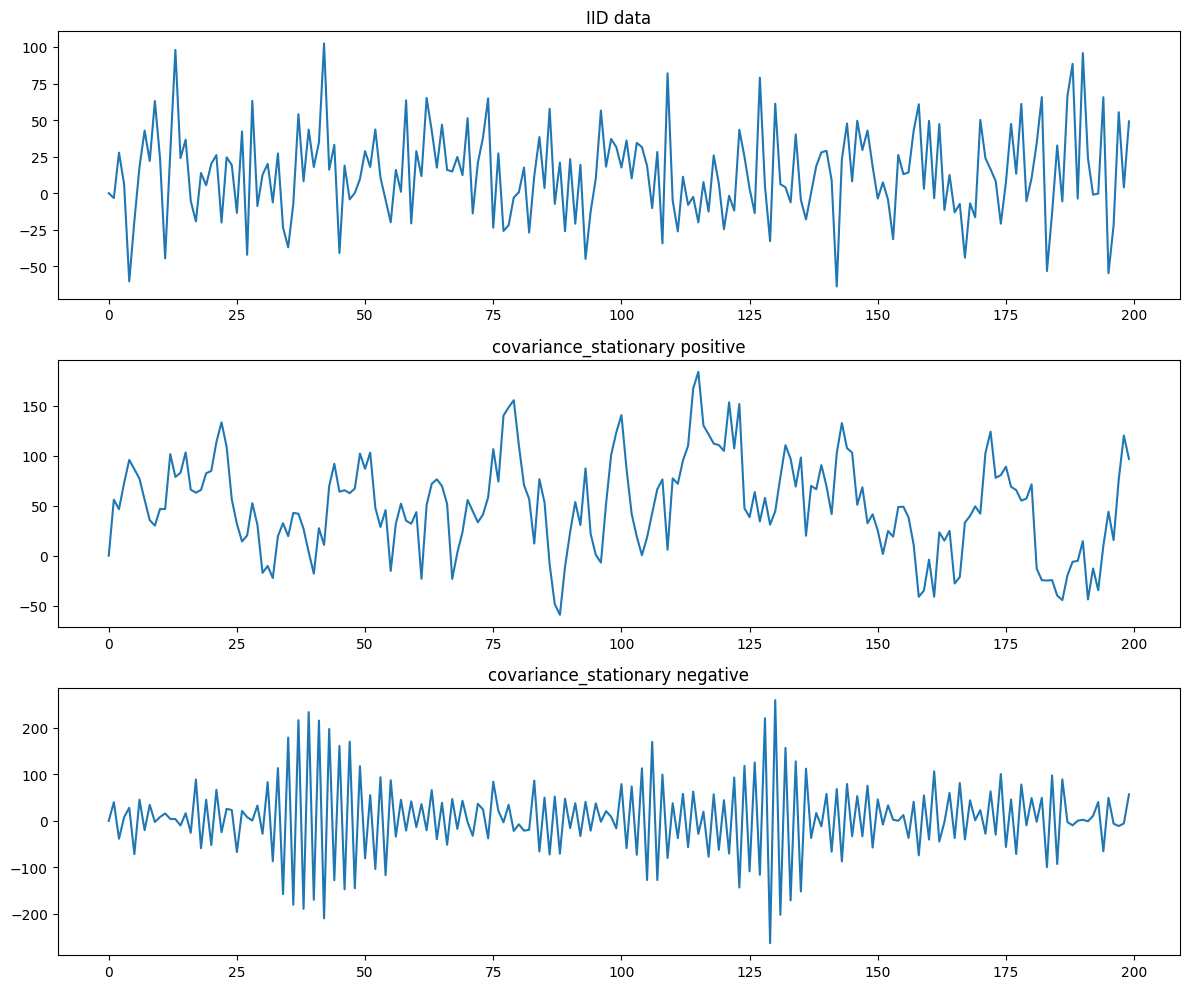

********** IID **********
Lag 0 autocorelation: 1.00
Lag 1 autocorelation: -0.06
Lag 2 autocorelation: 0.06
Lag 3 autocorelation: -0.00
True Mean: 10, True_standard_deviation: 30
Estimated Mean: 13.72, Estimated_standard_deviation: 30.572052

********** Positive **********
Lag 0 autocorelation: 1.00
Lag 1 autocorelation: 0.74
Lag 2 autocorelation: 0.56
Lag 3 autocorelation: 0.37
True Mean: 10, True_standard_deviation: 30
Estimated Mean: 50.62, Estimated_standard_deviation: 47.405598

********** Negative **********
Lag 0 autocorelation: 1.00
Lag 1 autocorelation: -0.93
Lag 2 autocorelation: 0.86
Lag 3 autocorelation: -0.80
True Mean: 10, True_standard_deviation: 30
Estimated Mean: 5.88, Estimated_standard_deviation: 84.645660


In [ ]:

def gen_covariance_stationary_data(phi,size,mean,std):
    xt = np.zeros(size)
    error = np.random.normal(mean,std,size)
    for t in range(1,size):
        xt[t]  = phi*xt[t-1] + error[t]
    return xt 

# ===== Data Generation: =====
true_mean = 10
true_std = 30
iid = gen_covariance_stationary_data(0,200,true_mean,true_std)
cov_sta_pos = gen_covariance_stationary_data(0.8,200,true_mean,true_std)
cov_sta_neg = gen_covariance_stationary_data(-0.9,200,true_mean,true_std)
fig,ax = plt.subplots(3,1,figsize=(12,10))

ax[0].set_title("IID data")
ax[0].plot(iid)

ax[1].set_title("covariance_stationary positive")
ax[1].plot(cov_sta_pos)

ax[2].set_title("covariance_stationary negative")
ax[2].plot(cov_sta_neg)
plt.tight_layout()
plt.show()


# ======== 1. check the IID data: ========
print("="*50)
print("*"*10,"IID","*"*10)
autocor = autocorelation(iid)
print(f"Lag 0 autocorelation: {autocor[0]:.2f}")
print(f"Lag 1 autocorelation: {autocor[1]:.2f}")
print(f"Lag 2 autocorelation: {autocor[2]:.2f}")
print(f"Lag 3 autocorelation: {autocor[3]:.2f}")
print("="*50)

print(f"True Mean: {true_mean}, True_standard_deviation: {true_std}")
print(f"Estimated Mean: {iid.mean():.2f}, Estimated_standard_deviation: {iid.std():2f}")


# ======== 2. check the positive covariance stationary :========
print()
print("="*50)
print("*"*10,"Positive","*"*10)
autocor = autocorelation(cov_sta_pos)
print(f"Lag 0 autocorelation: {autocor[0]:.2f}")
print(f"Lag 1 autocorelation: {autocor[1]:.2f}")
print(f"Lag 2 autocorelation: {autocor[2]:.2f}")
print(f"Lag 3 autocorelation: {autocor[3]:.2f}")
print("="*50)

print(f"True Mean: {true_mean}, True_standard_deviation: {true_std}")
print(f"Estimated Mean: {cov_sta_pos.mean():.2f}, Estimated_standard_deviation: {cov_sta_pos.std():2f}")


# ======== 3. check the negative covariance stationary: ========
print()
print("="*50)
print("*"*10,"Negative","*"*10)
autocor = autocorelation(cov_sta_neg)
print(f"Lag 0 autocorelation: {autocor[0]:.2f}")
print(f"Lag 1 autocorelation: {autocor[1]:.2f}")
print(f"Lag 2 autocorelation: {autocor[2]:.2f}")
print(f"Lag 3 autocorelation: {autocor[3]:.2f}")
print("="*50)

print(f"True Mean: {true_mean}, True_standard_deviation: {true_std}")
print(f"Estimated Mean: {cov_sta_neg.mean():.2f}, Estimated_standard_deviation: {cov_sta_neg.std():2f}")



<br>

# Confidence Intervals:

<br>

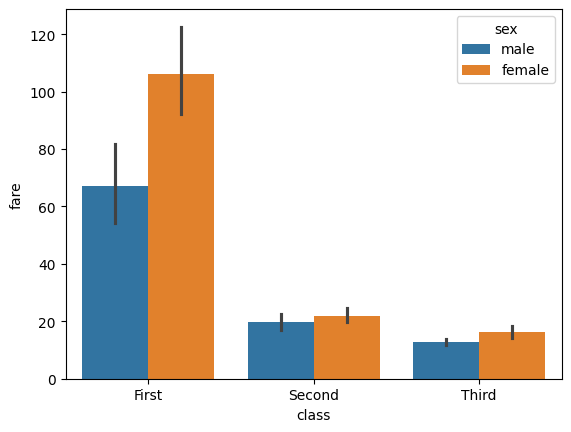

In [4]:
sns.barplot(data=titanic,x="class",y="fare",hue="sex")
plt.show()

<br>
<br>

# CTL: 

<br>
<br>

(1000,)


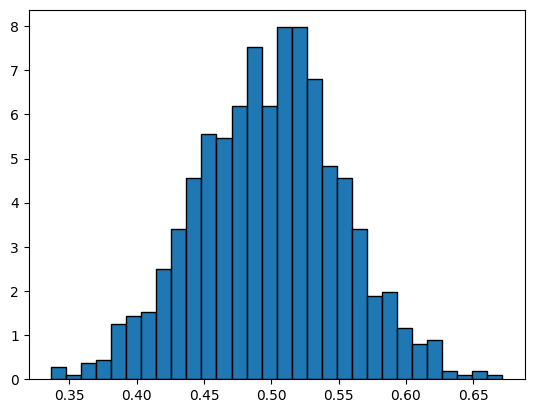

In [ ]:

# uniform distribution: 
sample1 = np.random.uniform(low=0,high=1,size=(1000,30))
mean1 = np.mean(sample1,axis=1)
print(mean1.shape)
plt.hist(x=mean1,bins=30,density=True,edgecolor="black")
plt.show()

[[0.         0.03333333 0.06666667 0.1       ]
 [0.03333333 0.06666667 0.1        0.13333333]
 [0.06666667 0.1        0.13333333 0.16666667]]

Marginal Probability Px(X):
 0    0.200000
1    0.333333
2    0.466667
dtype: float64

Marginal Probability Py(X):
 0    0.1
1    0.2
2    0.3
3    0.4
dtype: float64

CDF of F_X:
 0    0.200000
1    0.533333
2    1.000000
dtype: float64

CDF of F_Y:
 0    0.1
1    0.3
2    0.6
3    1.0
dtype: float64


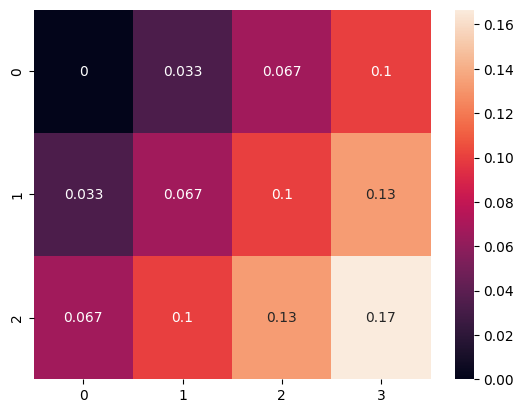

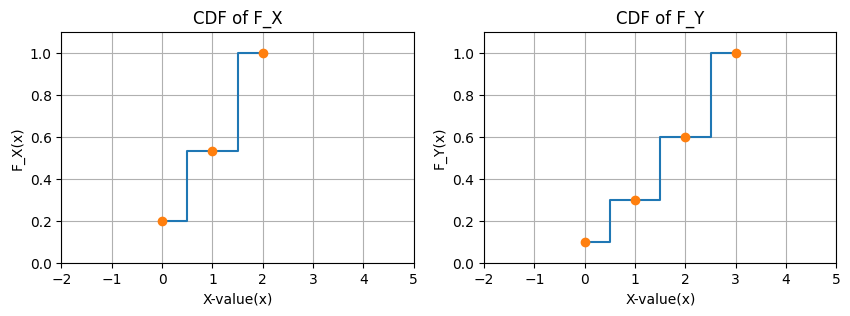

In [ ]:

# =========== Book Question: 4.4 ===========
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# uniform distribution: 
sample1 = np.random.uniform(low=0,high=1,size=(1000,30))
mean1 = np.mean(sample1,axis=1)
print(mean1.shape)
plt.hist(x=mean1,bins=30,density=True,edgecolor="black")
plt.show()

def p(x,y):
    if x in [0,1,2] and y in [0,1,2,3]:
        return (x+y)/30
    return 0

x_vals = [0,1,2]
y_vals = [0,1,2,3]

joint = np.zeros((len(x_vals), len(y_vals))) 

for i,x_val in enumerate(x_vals):
    for j,y_val in enumerate(y_vals):
        joint[i,j] = p(x_val,y_val)

df = pd.DataFrame(joint)

#1.Heatmaps
print(joint)
sns.heatmap(data=df,annot=True)


#2. Marginal
p_x = df.sum(axis=1)
p_y = df.sum(axis=0)
print(f"\nMarginal Probability Px(X):\n",p_x)
print(f"\nMarginal Probability Py(X):\n",p_y)

#3. CDF:
f_x = np.cumsum(p_x)
f_y = np.cumsum(p_y)
print("\nCDF of F_X:\n",f_x)
print("\nCDF of F_Y:\n",f_y)


# plot CDF:
fig,ax = plt.subplots(1,2,figsize=(10,3))


ax[0].step(x=x_vals,y=f_x,where="mid")
ax[0].plot(x_vals,f_x,'o')
ax[0].set_title("CDF of F_X")
ax[0].set_xlabel("X-value(x)")
ax[0].set_ylabel("F_X(x)")
ax[0].grid(True)
ax[0].set_xlim(-2,5)
ax[0].set_ylim(0,1.1)

ax[1].step(x=y_vals,y=f_y,where="mid")
ax[1].plot(y_vals,f_y,'o')
ax[1].set_title("CDF of F_Y")
ax[1].set_xlabel("X-value(x)")
ax[1].set_ylabel("F_Y(x)")
ax[1].grid(True)
ax[1].set_xlim(-2,5)
ax[1].set_ylim(0,1.1)

plt.show()

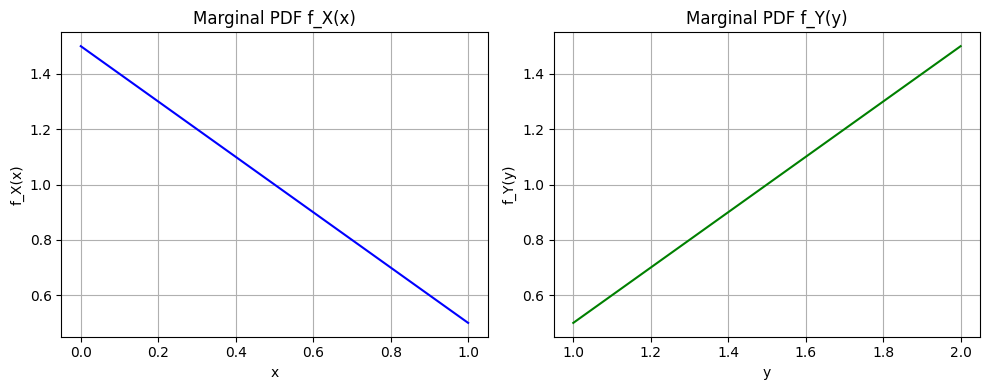

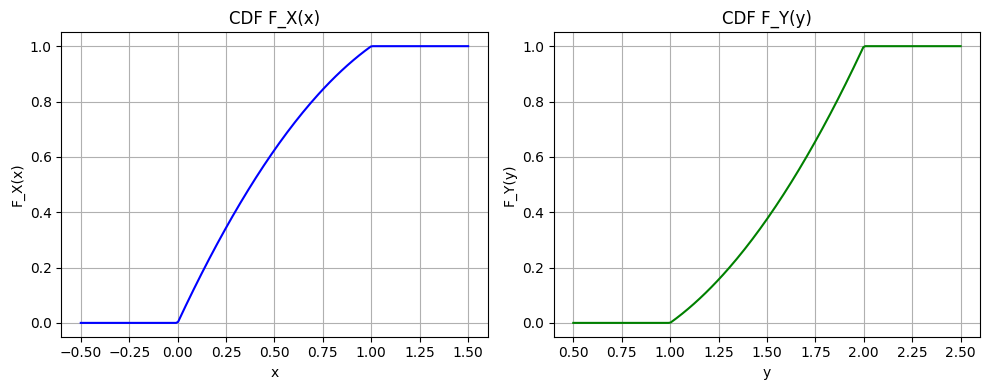

In [125]:

# =========== Book Question: 4.7 ===========
import numpy as np
import matplotlib.pyplot as plt

# f_X(x)
x = np.linspace(0, 1, 100)
f_x = 1.5 - x
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, f_x, color='blue')
plt.title('Marginal PDF f_X(x)')
plt.xlabel('x')
plt.ylabel('f_X(x)')
plt.grid(True)

# f_Y(y)
y = np.linspace(1, 2, 100)
f_y = y - 0.5
plt.subplot(1, 2, 2)
plt.plot(y, f_y, color='green')
plt.title('Marginal PDF f_Y(y)')
plt.xlabel('y')
plt.ylabel('f_Y(y)')
plt.grid(True)

plt.tight_layout()



# F_X(x)
x_full = np.linspace(-0.5, 1.5, 200)
f_x_cum = np.where(x_full < 0, 0, np.where(x_full >= 1, 1, 1.5*x_full - 0.5*x_full**2))
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x_full, f_x_cum, color='blue')
plt.title('CDF F_X(x)')
plt.xlabel('x')
plt.ylabel('F_X(x)')
plt.grid(True)

# F_Y(y)
y_full = np.linspace(0.5, 2.5, 200)
f_y_cum = np.where(y_full < 1, 0, np.where(y_full >= 2, 1, 0.5*y_full**2 - 0.5*y_full))
plt.subplot(1, 2, 2)
plt.plot(y_full, f_y_cum, color='green')
plt.title('CDF F_Y(y)')
plt.xlabel('y')
plt.ylabel('F_Y(y)')
plt.grid(True)

plt.tight_layout()
plt.show()